## Log Transformations

### The problem

The marketing team at the bank asks:

> *"If a client's income goes up 10%, how much more will they spend with their card?"*

That is a question about **percentages**, not about pesos. A regular linear model answers in pesos, and it may not fit this kind of data well. A **log transformation** can fix that, and it lets us answer in percentages.

### The data

We have **520 bank clients** and how much each one spends per month with their card. 

| Variable | Description |
|---|---|
| `gasto_tarjeta_mensual` | Monthly card spending in pesos (**what we want to explain**) |
| `ingreso_mensual` | Monthly income in pesos (**the variable of the marketing question**) |
| `score_buro` | Credit bureau score (400–850) |
| `edad_cliente` | Age in years |
| `antiguedad_laboral_meses` | Months at the current job |
| `num_productos_banco` | Number of bank products held |
| `tipo_empleo` | Asalariado / Independiente / Negocio Propio |
| `historial_pagos` | Bueno / Regular / Malo |

### What we will do

1. Look at the data to see if a log makes sense.
2. Fit four models (**LIN–LIN, LIN–LOG, LOG–LIN, LOG–LOG**) and check the same diagnostics in each one.
3. Read the coefficients of each model.
4. Compare them and choose the best model to answer the marketing team.

The dataset is already clean, so we go straight to modeling.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

sns.set_style("whitegrid")

---
## Load and prepare the data

In [46]:
spend = pd.read_csv("Gasto_Tarjeta_Data.csv")
print(spend.shape)
spend.head()

(520, 9)


,cliente_id,ingreso_mensual,score_buro,edad_cliente,antiguedad_laboral_meses,num_productos_banco,tipo_empleo,historial_pagos,gasto_tarjeta_mensual
0,C1000,26014,563,33,238,1,Negocio Propio,Bueno,1541.47
1,C1001,12417,570,33,257,6,Asalariado,Regular,1372.66
2,C1002,33241,770,59,256,6,Asalariado,Regular,3827.63
3,C1003,36905,633,44,59,2,Asalariado,Bueno,2157.45
4,C1004,7523,776,51,279,6,Asalariado,Regular,1077.55


Setup: reference categories **Asalariado** and **Bueno**, income in thousands of pesos, and an 80/20 train/test split with `random_state = 42`. Spending stays in **pesos**.

In [47]:
spend["tipo_empleo"] = pd.Categorical(spend["tipo_empleo"], categories=["Asalariado", "Independiente", "Negocio Propio"])
spend["historial_pagos"] = pd.Categorical(spend["historial_pagos"], categories=["Bueno", "Regular", "Malo"])
dummies = pd.get_dummies(spend[["tipo_empleo", "historial_pagos"]], drop_first=True, dtype=float)
dummies.columns = dummies.columns.str.replace(" ", "_")

spend_df = pd.concat([spend[["gasto_tarjeta_mensual", "score_buro", "edad_cliente",
                             "antiguedad_laboral_meses", "num_productos_banco"]], dummies], axis=1)
spend_df["ingreso_miles"] = spend["ingreso_mensual"] / 1000          # thousands of pesos

spend_train, spend_test = train_test_split(spend_df, test_size=0.2, random_state=42)
y_test = spend_test["gasto_tarjeta_mensual"]

otros = " + ".join(c for c in spend_df.columns if c not in ("gasto_tarjeta_mensual", "ingreso_miles"))
print(spend_train.shape, spend_test.shape)
print("Other predictors:", otros)

(416, 10) (104, 10)
Other predictors: score_buro + edad_cliente + antiguedad_laboral_meses + num_productos_banco + tipo_empleo_Independiente + tipo_empleo_Negocio_Propio + historial_pagos_Regular + historial_pagos_Malo


**Interpretation:** 416 clients for training and 104 for testing. `otros` holds the predictors that will stay in levels in every model.

---
## Step 1 — Before modeling: why a log?

Three questions decide whether a variable deserves a log (they come from the *"Does this variable deserve a log?"* slide):

1. Is it **strictly positive**? (the log does not exist for zero or negative values)
2. Is it **right-skewed**, with a long tail?
3. Are its effects expected to be **proportional**, not a fixed amount?

Let us check the numeric variables one by one.

In [48]:
numeric_vars = ["gasto_tarjeta_mensual", "ingreso_mensual", "score_buro", "edad_cliente",
                "antiguedad_laboral_meses", "num_productos_banco"]
pd.DataFrame({
    "min": spend[numeric_vars].min(),
    "median": spend[numeric_vars].median(),
    "max": spend[numeric_vars].max(),
    "skewness": spend[numeric_vars].skew(),
}).round(2)

,min,median,max,skewness
gasto_tarjeta_mensual,487.84,1821.59,8350.13,1.61
ingreso_mensual,6000.00,22108.00,109253.00,1.92
score_buro,400.00,650.50,850.00,-0.17
edad_cliente,18.00,40.00,65.00,0.11
antiguedad_laboral_meses,5.00,150.50,299.00,0.03
num_productos_banco,1.00,4.00,8.00,0.01


**Interpretation:**

| Variable | Skewness | Decision |
|---|---|---|
| `gasto_tarjeta_mensual` | 1.61 | **Log candidate on y**: positive, long right tail, proportional effects |
| `ingreso_mensual` | 1.92 | **Log candidate on x**: positive, long right tail |
| `score_buro` | -0.17 | Keep in levels: bounded (400–850) and symmetric |
| `edad_cliente` | 0.11 | Keep in levels: symmetric, and one year already has a natural meaning |
| `antiguedad_laboral_meses` | 0.03 | Keep in levels: symmetric |
| `num_productos_banco` | 0.01 | Keep in levels: a small count, symmetric |

Only **spending and income** show a long right tail. Those are the two variables we will try with a log. The categorical variables stay as dummies in every model (a dummy can never be logged).

### See what the log does to the distributions

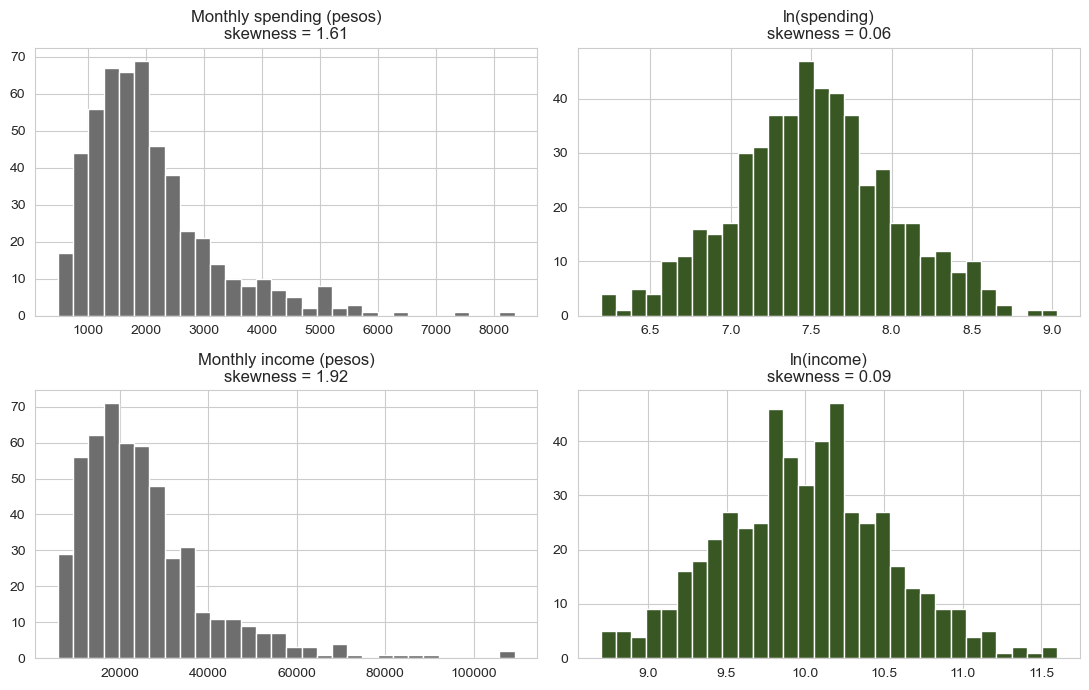

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].hist(spend["gasto_tarjeta_mensual"], bins=30, color="#6E6E6E", edgecolor="white")
axes[0, 0].set_title(f"Monthly spending (pesos)\nskewness = {spend['gasto_tarjeta_mensual'].skew():.2f}")
axes[0, 1].hist(np.log(spend["gasto_tarjeta_mensual"]), bins=30, color="#395723", edgecolor="white")
axes[0, 1].set_title(f"ln(spending)\nskewness = {np.log(spend['gasto_tarjeta_mensual']).skew():.2f}")

axes[1, 0].hist(spend["ingreso_mensual"], bins=30, color="#6E6E6E", edgecolor="white")
axes[1, 0].set_title(f"Monthly income (pesos)\nskewness = {spend['ingreso_mensual'].skew():.2f}")
axes[1, 1].hist(np.log(spend["ingreso_mensual"]), bins=30, color="#395723", edgecolor="white")
axes[1, 1].set_title(f"ln(income)\nskewness = {np.log(spend['ingreso_mensual']).skew():.2f}")

plt.tight_layout()
plt.show()

**Interpretation:** this is the reason for using a log. On the **left**, both variables have a long right tail (skewness 1.61 and 1.92): a few clients with very large values stretch the scale. On the **right**, after `np.log()`, both become almost symmetric (skewness 0.06 and 0.09). The log **compresses the large values and gives room to the small ones**.

### See what the log does to the relationship

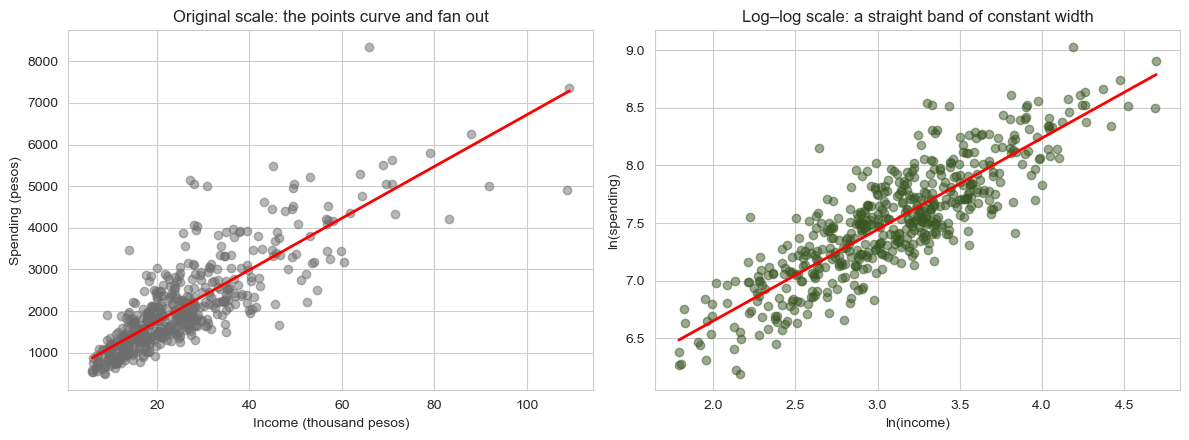

In [50]:
x_all, y_all = spend_df["ingreso_miles"], spend_df["gasto_tarjeta_mensual"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(x_all, y_all, alpha=0.5, color="#6E6E6E")
slope, intercept = np.polyfit(x_all, y_all, 1)
grid = np.linspace(x_all.min(), x_all.max(), 100)
axes[0].plot(grid, intercept + slope * grid, color="red", linewidth=2)
axes[0].set(xlabel="Income (thousand pesos)", ylabel="Spending (pesos)", title="Original scale: the points curve and fan out")

axes[1].scatter(np.log(x_all), np.log(y_all), alpha=0.5, color="#395723")
slope, intercept = np.polyfit(np.log(x_all), np.log(y_all), 1)
grid = np.linspace(np.log(x_all.min()), np.log(x_all.max()), 100)
axes[1].plot(grid, intercept + slope * grid, color="red", linewidth=2)
axes[1].set(xlabel="ln(income)", ylabel="ln(spending)", title="Log–log scale: a straight band of constant width")

plt.tight_layout()
plt.show()

**Interpretation:** on the original scale (left) the cloud **bends** (spending grows more slowly at high incomes) and **fans out** (the spread is larger for high-income clients). A straight line cannot describe that well. After taking the log of both variables (right), the cloud becomes a **straight band of roughly constant width**, which is exactly what a linear model assumes.

This is a *preview*, not a proof. The rest of the notebook checks it properly, model by model.

---
## Step 2 — LIN–LIN: the baseline

$$\text{gasto} = \beta_0 + \beta_1 \cdot \text{ingreso} + \dots + \varepsilon$$

For every model we do the same three things: fit it, look at the diagnostic plots, and run the tests. How to read the three plots:

- **Left, residuals vs. fitted (linearity and constant spread):** we want a random band around 0. A bend (a U shape) means the model is missing a curve. A funnel (the spread grows with the fitted value) means the variance is not constant.
- **Middle, histogram (normality):** it should look like a bell.
- **Right, Q–Q plot (normality):** the points should follow the diagonal.

### The tests we will run: which assumption, which hypotheses

Every model must satisfy the same four assumptions. Each one has a test, with a null hypothesis ($H_0$) and an alternative ($H_1$). We use $\alpha = 0.05$.

| Assumption | Test | $H_0$ | $H_1$ | Decision |
|---|---|---|---|---|
| **Linearity** (correct functional form) | Ramsey RESET | The model is correctly specified (it is linear in the predictors) | The model is misspecified (for example, it misses a curve) | $p < 0.05$: reject $H_0$, linearity is violated |
| **Constant spread** (homoscedasticity) | Breusch-Pagan | The variance of the errors is constant | The variance of the errors depends on the predictors | $p < 0.05$: reject $H_0$, there is a funnel |
| **Normality** of the errors | Jarque-Bera | The errors are normal (skewness 0, kurtosis 3) | The errors are not normal | $p < 0.05$: reject $H_0$, not normal |
| **Independence** of the errors | Durbin-Watson | There is no autocorrelation | There is autocorrelation | No p-value: DW close to 2 means no autocorrelation |

Two reminders:

- **Not rejecting $H_0$ does not prove the assumption holds.** It only means we found no evidence against it.
- **Normality is judged first with the histogram and the Q–Q plot.** With 416 observations, Jarque-Bera flags even small departures, so we read it together with the plot and with the skewness and kurtosis.

In [51]:
modelo_ll = smf.ols("gasto_tarjeta_mensual ~ ingreso_miles + " + otros, data=spend_train).fit()
modelo_ll.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-1468.6483,201.313,-7.295,0.000,-1864.395,-1072.901
ingreso_miles,63.0193,1.641,38.399,0.000,59.793,66.245
score_buro,2.6297,0.273,9.618,0.000,2.092,3.167
edad_cliente,1.2797,1.695,0.755,0.451,-2.053,4.612
antiguedad_laboral_meses,1.0402,0.290,3.592,0.000,0.471,1.610
num_productos_banco,56.0254,10.428,5.372,0.000,35.525,76.526
tipo_empleo_Independiente,-310.8642,62.385,-4.983,0.000,-433.503,-188.226
tipo_empleo_Negocio_Propio,-147.8512,61.857,-2.390,0.017,-269.451,-26.252
historial_pagos_Regular,-239.2950,49.574,-4.827,0.000,-336.748,-141.842
historial_pagos_Malo,-353.4158,116.493,-3.034,0.003,-582.421,-124.411


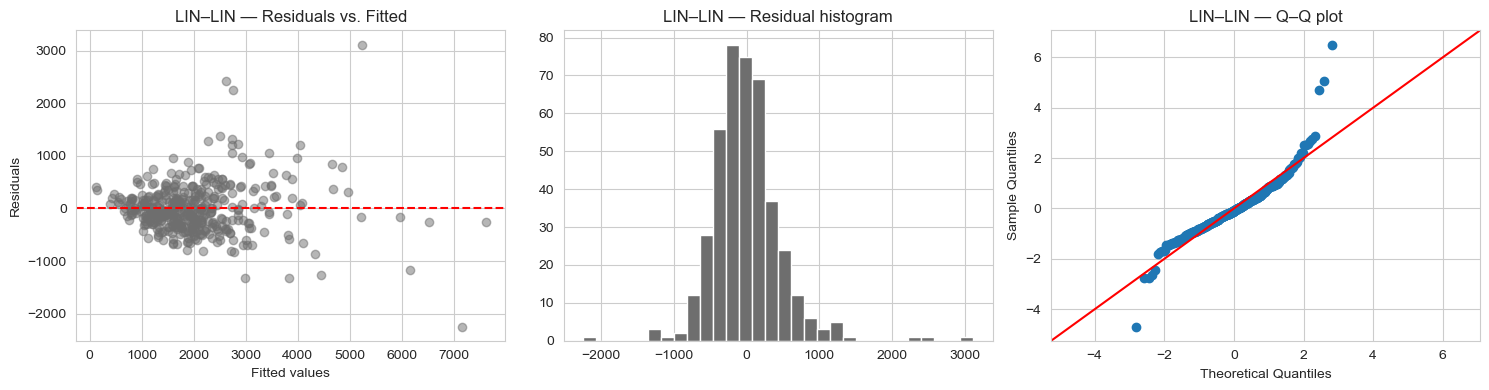

In [52]:
fitted, resid = modelo_ll.fittedvalues, modelo_ll.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuals vs. fitted: linearity (bend?) and constant spread (funnel?)
axes[0].scatter(fitted, resid, alpha=0.5, color="#6E6E6E")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="LIN–LIN — Residuals vs. Fitted")

# Normality: histogram and Q–Q plot
axes[1].hist(resid, bins=30, color="#6E6E6E", edgecolor="white")
axes[1].set_title("LIN–LIN — Residual histogram")

sm.qqplot(resid, line="45", fit=True, ax=axes[2])
axes[2].set_title("LIN–LIN — Q–Q plot")

plt.tight_layout()
plt.show()

In [53]:
reset_ll = linear_reset(modelo_ll, power=3, use_f=True)
bp_ll = het_breuschpagan(modelo_ll.resid, modelo_ll.model.exog)
jb_ll = jarque_bera(modelo_ll.resid)
dw_ll = durbin_watson(modelo_ll.resid)

print("LINEARITY        Ramsey RESET   (H0: the model is correctly specified)")
print(f"                 F = {float(reset_ll.fvalue):.2f},  p = {float(reset_ll.pvalue):.4g}\n")
print("CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)")
print(f"                 p = {bp_ll[1]:.4g}\n")
print("NORMALITY        Jarque-Bera    (H0: the errors are normal)")
print(f"                 p = {jb_ll[1]:.4g}   (skewness = {jb_ll[2]:.2f}, kurtosis = {jb_ll[3]:.2f}; a normal has 0 and 3)\n")
print("INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)")
print(f"                 DW = {dw_ll:.2f}\n")

# Test set, always in pesos (for log(y) models we bring the prediction back with np.exp)
pred_ll = modelo_ll.predict(spend_test)
mae_ll = mean_absolute_error(y_test, pred_ll)
mape_ll = mean_absolute_percentage_error(y_test, pred_ll) * 100
rmse_ll = np.sqrt(mean_squared_error(y_test, pred_ll))
print(f"TEST SET (pesos)  MAE = {mae_ll:,.1f}   MAPE = {mape_ll:.2f}%   RMSE = {rmse_ll:,.1f}")

LINEARITY        Ramsey RESET   (H0: the model is correctly specified)
                 F = 10.66,  p = 3.08e-05

CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)
                 p = 7.794e-09

NORMALITY        Jarque-Bera    (H0: the errors are normal)
                 p = 9.765e-225   (skewness = 1.14, kurtosis = 10.37; a normal has 0 and 3)

INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)
                 DW = 2.17

TEST SET (pesos)  MAE = 410.5   MAPE = 17.92%   RMSE = 564.6


**Tests (LIN–LIN, α = 0.05):**

| Assumption | Test | Result | Decision |
|---|---|---|---|
| Linearity | Ramsey RESET | F = 10.66, p < 0.001 | **Reject H₀**: linearity is violated |
| Constant spread | Breusch-Pagan | p < 0.001 | **Reject H₀**: the spread is not constant (funnel) |
| Normality | Jarque-Bera | p < 0.001 | **Reject H₀**: the residuals are not normal |
| Independence | Durbin-Watson | DW = 2.17 | About 2: no sign of autocorrelation |

**Interpretation:** LIN–LIN shows **all three symptoms at once**:

- **Curvature:** RESET rejects ($F$ = 10.66, $p$ < 0.001).
- **Funnel:** the spread of the residuals grows with the fitted value (left plot), and Breusch-Pagan rejects ($p$ < 0.001).
- **Right-skewed residuals:** the histogram has a long right tail and the Q–Q plot bends away from the line at the upper end (skewness 1.14, kurtosis 10.37).

A straight line in pesos is the wrong shape for this data. Which log fixes which symptom? Let us find out, one at a time.

---
## Step 3 — LIN–LOG: log on x only

$$\text{gasto} = \beta_0 + \beta_1 \cdot \ln(\text{ingreso}) + \dots + \varepsilon$$

Symptom we are trying to fix: **curvature in x** (*"diminishing returns"* of income).

In [54]:
modelo_lg = smf.ols("gasto_tarjeta_mensual ~ np.log(ingreso_miles) + " + otros, data=spend_train).fit()
modelo_lg.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-4930.3515,270.221,-18.246,0.000,-5461.558,-4399.145
np.log(ingreso_miles),1668.5457,52.057,32.053,0.000,1566.212,1770.880
score_buro,2.5781,0.313,8.227,0.000,1.962,3.194
edad_cliente,0.8093,1.941,0.417,0.677,-3.007,4.625
antiguedad_laboral_meses,1.0363,0.332,3.124,0.002,0.384,1.689
num_productos_banco,47.7444,11.949,3.996,0.000,24.254,71.235
tipo_empleo_Independiente,-365.1538,71.418,-5.113,0.000,-505.548,-224.759
tipo_empleo_Negocio_Propio,-139.5873,70.847,-1.970,0.049,-278.860,-0.315
historial_pagos_Regular,-212.0241,56.741,-3.737,0.000,-323.566,-100.482
historial_pagos_Malo,-407.4808,133.376,-3.055,0.002,-669.675,-145.286


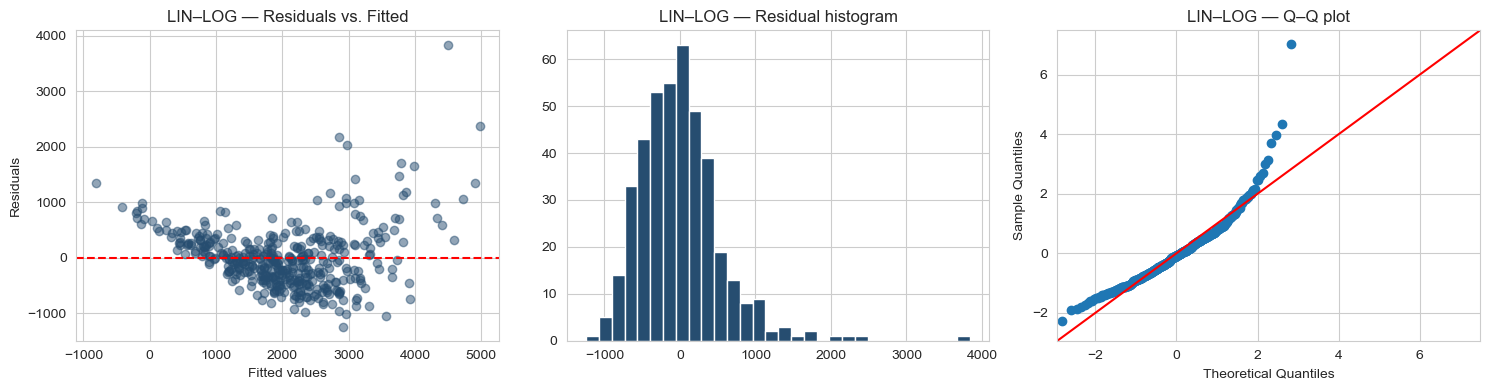

In [55]:
fitted, resid = modelo_lg.fittedvalues, modelo_lg.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuals vs. fitted: linearity (bend?) and constant spread (funnel?)
axes[0].scatter(fitted, resid, alpha=0.5, color="#264D70")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="LIN–LOG — Residuals vs. Fitted")

# Normality: histogram and Q–Q plot
axes[1].hist(resid, bins=30, color="#264D70", edgecolor="white")
axes[1].set_title("LIN–LOG — Residual histogram")

sm.qqplot(resid, line="45", fit=True, ax=axes[2])
axes[2].set_title("LIN–LOG — Q–Q plot")

plt.tight_layout()
plt.show()

In [56]:
reset_lg = linear_reset(modelo_lg, power=3, use_f=True)
bp_lg = het_breuschpagan(modelo_lg.resid, modelo_lg.model.exog)
jb_lg = jarque_bera(modelo_lg.resid)
dw_lg = durbin_watson(modelo_lg.resid)

print("LINEARITY        Ramsey RESET   (H0: the model is correctly specified)")
print(f"                 F = {float(reset_lg.fvalue):.2f},  p = {float(reset_lg.pvalue):.4g}\n")
print("CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)")
print(f"                 p = {bp_lg[1]:.4g}\n")
print("NORMALITY        Jarque-Bera    (H0: the errors are normal)")
print(f"                 p = {jb_lg[1]:.4g}   (skewness = {jb_lg[2]:.2f}, kurtosis = {jb_lg[3]:.2f}; a normal has 0 and 3)\n")
print("INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)")
print(f"                 DW = {dw_lg:.2f}\n")

# Test set, always in pesos (for log(y) models we bring the prediction back with np.exp)
pred_lg = modelo_lg.predict(spend_test)
mae_lg = mean_absolute_error(y_test, pred_lg)
mape_lg = mean_absolute_percentage_error(y_test, pred_lg) * 100
rmse_lg = np.sqrt(mean_squared_error(y_test, pred_lg))
print(f"TEST SET (pesos)  MAE = {mae_lg:,.1f}   MAPE = {mape_lg:.2f}%   RMSE = {rmse_lg:,.1f}")

LINEARITY        Ramsey RESET   (H0: the model is correctly specified)
                 F = 101.43,  p = 2.015e-36

CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)
                 p = 4.211e-05

NORMALITY        Jarque-Bera    (H0: the errors are normal)
                 p = 1.487e-212   (skewness = 1.59, kurtosis = 9.80; a normal has 0 and 3)

INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)
                 DW = 2.12

TEST SET (pesos)  MAE = 448.7   MAPE = 22.17%   RMSE = 587.9


**Tests (LIN–LOG, α = 0.05):**

| Assumption | Test | Result | Decision |
|---|---|---|---|
| Linearity | Ramsey RESET | F = 101.43, p < 0.001 | **Reject H₀**: linearity is violated |
| Constant spread | Breusch-Pagan | p < 0.001 | **Reject H₀**: the spread is not constant (funnel) |
| Normality | Jarque-Bera | p < 0.001 | **Reject H₀**: the residuals are not normal |
| Independence | Durbin-Watson | DW = 2.12 | About 2: no sign of autocorrelation |

**Interpretation:** putting a log on `x` **alone does not solve it**. RESET still rejects ($F$ = 101.43, even larger than LIN–LIN), the funnel is still there (Breusch-Pagan $p$ < 0.001), and the residuals are still right-skewed (1.59). We bent `x` but `y` is still on the original scale, where the spread grows with the level. We fixed one problem and left the other.

---
## Step 4 — LOG–LIN: log on y only

$$\ln(\text{gasto}) = \beta_0 + \beta_1 \cdot \text{ingreso} + \dots + \varepsilon$$

Symptom we are trying to fix: **funnel and right-skewed residuals** (proportional errors).

In [57]:
modelo_gl = smf.ols("np.log(gasto_tarjeta_mensual) ~ ingreso_miles + " + otros, data=spend_train).fit()
modelo_gl.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,5.8250,0.106,55.026,0.000,5.617,6.033
ingreso_miles,0.0265,0.001,30.707,0.000,0.025,0.028
score_buro,0.0014,0.000,9.831,0.000,0.001,0.002
edad_cliente,-0.0002,0.001,-0.252,0.801,-0.002,0.002
antiguedad_laboral_meses,0.0004,0.000,2.841,0.005,0.000,0.001
num_productos_banco,0.0312,0.005,5.696,0.000,0.020,0.042
tipo_empleo_Independiente,-0.1625,0.033,-4.952,0.000,-0.227,-0.098
tipo_empleo_Negocio_Propio,-0.0599,0.033,-1.843,0.066,-0.124,0.004
historial_pagos_Regular,-0.1035,0.026,-3.970,0.000,-0.155,-0.052
historial_pagos_Malo,-0.2099,0.061,-3.427,0.001,-0.330,-0.089


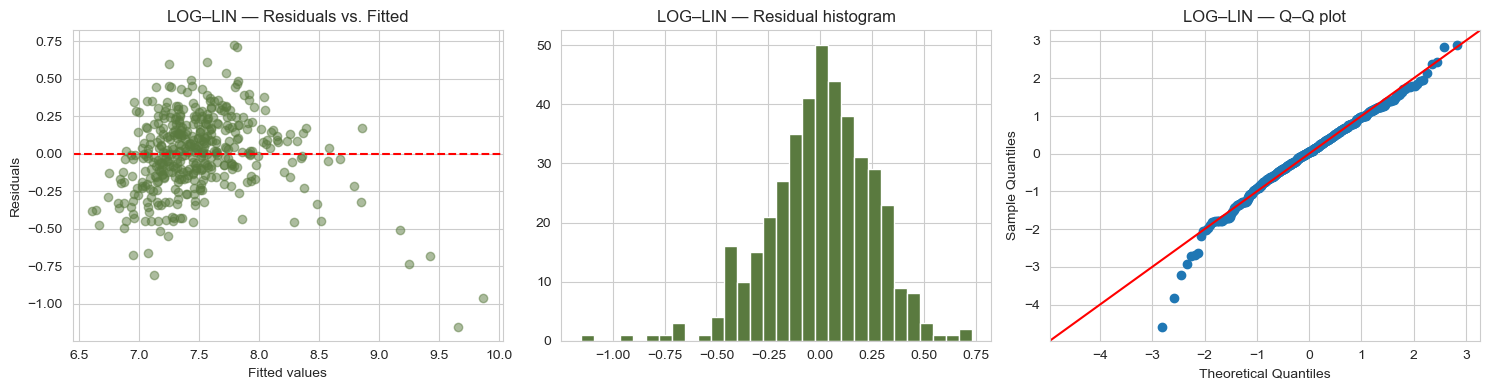

In [58]:
fitted, resid = modelo_gl.fittedvalues, modelo_gl.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuals vs. fitted: linearity (bend?) and constant spread (funnel?)
axes[0].scatter(fitted, resid, alpha=0.5, color="#5A7A3F")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="LOG–LIN — Residuals vs. Fitted")

# Normality: histogram and Q–Q plot
axes[1].hist(resid, bins=30, color="#5A7A3F", edgecolor="white")
axes[1].set_title("LOG–LIN — Residual histogram")

sm.qqplot(resid, line="45", fit=True, ax=axes[2])
axes[2].set_title("LOG–LIN — Q–Q plot")

plt.tight_layout()
plt.show()

In [59]:
reset_gl = linear_reset(modelo_gl, power=3, use_f=True)
bp_gl = het_breuschpagan(modelo_gl.resid, modelo_gl.model.exog)
jb_gl = jarque_bera(modelo_gl.resid)
dw_gl = durbin_watson(modelo_gl.resid)

print("LINEARITY        Ramsey RESET   (H0: the model is correctly specified)")
print(f"                 F = {float(reset_gl.fvalue):.2f},  p = {float(reset_gl.pvalue):.4g}\n")
print("CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)")
print(f"                 p = {bp_gl[1]:.4g}\n")
print("NORMALITY        Jarque-Bera    (H0: the errors are normal)")
print(f"                 p = {jb_gl[1]:.4g}   (skewness = {jb_gl[2]:.2f}, kurtosis = {jb_gl[3]:.2f}; a normal has 0 and 3)\n")
print("INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)")
print(f"                 DW = {dw_gl:.2f}\n")

# Test set, always in pesos (for log(y) models we bring the prediction back with np.exp)
pred_gl = np.exp(modelo_gl.predict(spend_test))
mae_gl = mean_absolute_error(y_test, pred_gl)
mape_gl = mean_absolute_percentage_error(y_test, pred_gl) * 100
rmse_gl = np.sqrt(mean_squared_error(y_test, pred_gl))
print(f"TEST SET (pesos)  MAE = {mae_gl:,.1f}   MAPE = {mape_gl:.2f}%   RMSE = {rmse_gl:,.1f}")

LINEARITY        Ramsey RESET   (H0: the model is correctly specified)
                 F = 94.17,  p = 2.686e-34

CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)
                 p = 1.814e-05

NORMALITY        Jarque-Bera    (H0: the errors are normal)
                 p = 1.458e-11   (skewness = -0.51, kurtosis = 4.35; a normal has 0 and 3)

INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)
                 DW = 2.21

TEST SET (pesos)  MAE = 480.3   MAPE = 18.85%   RMSE = 743.4


**Tests (LOG–LIN, α = 0.05):**

| Assumption | Test | Result | Decision |
|---|---|---|---|
| Linearity | Ramsey RESET | F = 94.17, p < 0.001 | **Reject H₀**: linearity is violated |
| Constant spread | Breusch-Pagan | p < 0.001 | **Reject H₀**: the spread is not constant (funnel) |
| Normality | Jarque-Bera | p < 0.001 | **Reject H₀**: the residuals are not normal |
| Independence | Durbin-Watson | DW = 2.21 | About 2: no sign of autocorrelation |

**Interpretation:** now the **residual skewness improves** (-0.51, kurtosis 4.35, much closer to a normal's 0 and 3), because the log on `y` compresses the long tail. But the bend in the left plot is still there: RESET rejects very strongly ($F$ = 94.17) and Breusch-Pagan still rejects ($p$ < 0.001). This time we fixed the `y` problem and left the `x` problem.

---
## Step 5 — LOG–LOG: log on both

$$\ln(\text{gasto}) = \beta_0 + \beta_1 \cdot \ln(\text{ingreso}) + \dots + \varepsilon$$

Both symptoms together: curvature in `x` **and** proportional errors in `y`.

In [60]:
modelo_gg = smf.ols("np.log(gasto_tarjeta_mensual) ~ np.log(ingreso_miles) + " + otros, data=spend_train).fit()
modelo_gg.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,4.1030,0.095,43.319,0.000,3.917,4.289
np.log(ingreso_miles),0.7970,0.018,43.681,0.000,0.761,0.833
score_buro,0.0013,0.000,12.274,0.000,0.001,0.002
edad_cliente,-0.0002,0.001,-0.334,0.738,-0.002,0.001
antiguedad_laboral_meses,0.0004,0.000,3.833,0.000,0.000,0.001
num_productos_banco,0.0271,0.004,6.477,0.000,0.019,0.035
tipo_empleo_Independiente,-0.1835,0.025,-7.330,0.000,-0.233,-0.134
tipo_empleo_Negocio_Propio,-0.0634,0.025,-2.553,0.011,-0.112,-0.015
historial_pagos_Regular,-0.0978,0.020,-4.919,0.000,-0.137,-0.059
historial_pagos_Malo,-0.2242,0.047,-4.796,0.000,-0.316,-0.132


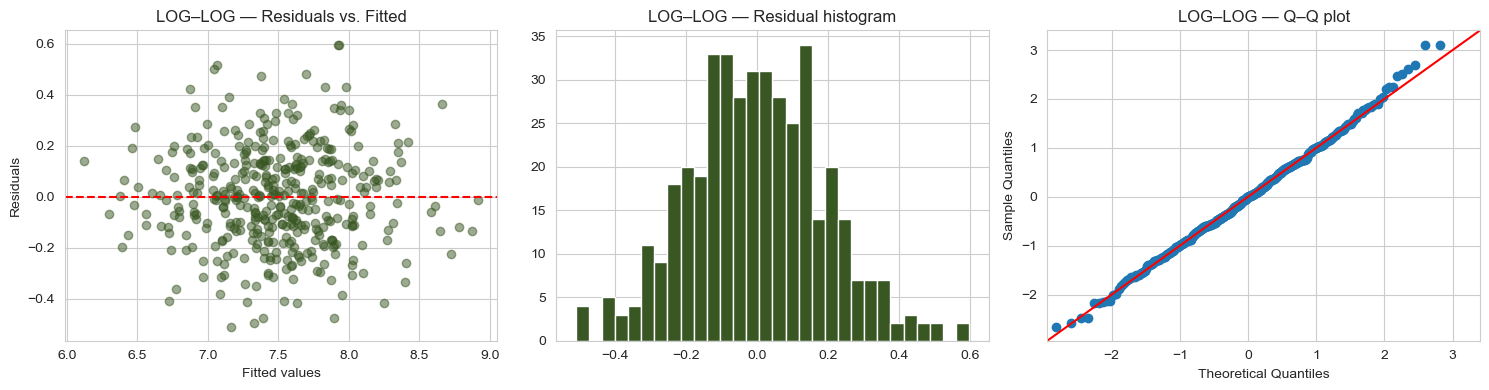

In [61]:
fitted, resid = modelo_gg.fittedvalues, modelo_gg.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuals vs. fitted: linearity (bend?) and constant spread (funnel?)
axes[0].scatter(fitted, resid, alpha=0.5, color="#395723")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="LOG–LOG — Residuals vs. Fitted")

# Normality: histogram and Q–Q plot
axes[1].hist(resid, bins=30, color="#395723", edgecolor="white")
axes[1].set_title("LOG–LOG — Residual histogram")

sm.qqplot(resid, line="45", fit=True, ax=axes[2])
axes[2].set_title("LOG–LOG — Q–Q plot")

plt.tight_layout()
plt.show()

In [62]:
reset_gg = linear_reset(modelo_gg, power=3, use_f=True)
bp_gg = het_breuschpagan(modelo_gg.resid, modelo_gg.model.exog)
jb_gg = jarque_bera(modelo_gg.resid)
dw_gg = durbin_watson(modelo_gg.resid)

print("LINEARITY        Ramsey RESET   (H0: the model is correctly specified)")
print(f"                 F = {float(reset_gg.fvalue):.2f},  p = {float(reset_gg.pvalue):.4g}\n")
print("CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)")
print(f"                 p = {bp_gg[1]:.4g}\n")
print("NORMALITY        Jarque-Bera    (H0: the errors are normal)")
print(f"                 p = {jb_gg[1]:.4g}   (skewness = {jb_gg[2]:.2f}, kurtosis = {jb_gg[3]:.2f}; a normal has 0 and 3)\n")
print("INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)")
print(f"                 DW = {dw_gg:.2f}\n")

# Test set, always in pesos (for log(y) models we bring the prediction back with np.exp)
pred_gg = np.exp(modelo_gg.predict(spend_test))
mae_gg = mean_absolute_error(y_test, pred_gg)
mape_gg = mean_absolute_percentage_error(y_test, pred_gg) * 100
rmse_gg = np.sqrt(mean_squared_error(y_test, pred_gg))
print(f"TEST SET (pesos)  MAE = {mae_gg:,.1f}   MAPE = {mape_gg:.2f}%   RMSE = {rmse_gg:,.1f}")

LINEARITY        Ramsey RESET   (H0: the model is correctly specified)
                 F = 0.36,  p = 0.6991

CONSTANT SPREAD  Breusch-Pagan  (H0: the variance of the errors is constant)
                 p = 0.5769

NORMALITY        Jarque-Bera    (H0: the errors are normal)
                 p = 0.5057   (skewness = 0.14, kurtosis = 3.06; a normal has 0 and 3)

INDEPENDENCE     Durbin-Watson  (no p-value; about 2 means no autocorrelation)
                 DW = 2.14

TEST SET (pesos)  MAE = 404.1   MAPE = 17.61%   RMSE = 552.1


**Tests (LOG–LOG, α = 0.05):**

| Assumption | Test | Result | Decision |
|---|---|---|---|
| Linearity | Ramsey RESET | F = 0.36, p = 0.699 | Do not reject H₀: no evidence against linearity |
| Constant spread | Breusch-Pagan | p = 0.577 | Do not reject H₀: no evidence of a funnel |
| Normality | Jarque-Bera | p = 0.506 | Do not reject H₀: consistent with normal residuals |
| Independence | Durbin-Watson | DW = 2.14 | About 2: no sign of autocorrelation |

**Interpretation:** this is the only model where **everything is clean**:

- **Linearity:** the left plot is a random band around 0, and RESET does not reject ($F$ = 0.36, $p$ = 0.699).
- **Constant spread:** no funnel, and Breusch-Pagan does not reject ($p$ = 0.577).
- **Normality:** the Q–Q plot follows the line, with skewness 0.14 and kurtosis 3.06 (very close to 0 and 3).

**The log has to go where the problem is.** Fixing only `x` (LIN–LOG) or only `y` (LOG–LIN) left one symptom behind; fixing both solved them together. That is exactly what the diagnostics table in the slides predicted.

---
## Step 6 — Reading the coefficients

Each model speaks a different language. Let us translate the coefficient of `ingreso_miles` in each one, using the **exact** formulas.

In [63]:
b = modelo_ll.params["ingreso_miles"]
print(f"LIN–LIN: β = {b:,.1f}  →  +1,000 pesos of income goes with {b:+,.1f} pesos of spending")

b = modelo_lg.params["np.log(ingreso_miles)"]
print(f"LIN–LOG: β = {b:,.1f}  →  +1% of income goes with {b / 100:+,.2f} pesos of spending   (β / 100)")

b = modelo_gl.params["ingreso_miles"]
print(f"LOG–LIN: β = {b:.4f}  →  +1,000 pesos of income goes with {100 * (np.exp(b) - 1):+.2f}% spending   (approx. {100 * b:+.2f}%)")

b = modelo_gg.params["np.log(ingreso_miles)"]
print(f"LOG–LOG: β = {b:.3f}  →  +1% of income goes with {100 * (1.01 ** b - 1):+.3f}% spending   (approx. {b:.3f}%)")

LIN–LIN: β = 63.0  →  +1,000 pesos of income goes with +63.0 pesos of spending
LIN–LOG: β = 1,668.5  →  +1% of income goes with +16.69 pesos of spending   (β / 100)
LOG–LIN: β = 0.0265  →  +1,000 pesos of income goes with +2.69% spending   (approx. +2.65%)
LOG–LOG: β = 0.797  →  +1% of income goes with +0.796% spending   (approx. 0.797%)


**Interpretation:**

| Model | β₁ | Reading |
|---|---|---|
| LIN–LIN | 63.0 | +1,000 pesos of income goes with +63.0 pesos of spending |
| LIN–LOG | 1,668.5 | +1% of income goes with +16.69 pesos of spending (β / 100) |
| LOG–LIN | 0.0265 | +1,000 pesos of income goes with +2.69% spending (approximation: 2.65%) |
| LOG–LOG | 0.797 | +1% of income goes with +0.796% spending (approximation: 0.797%) |

Two things to notice:

- **The units change with the model**, so the coefficients cannot be compared with each other directly. They answer different questions.
- **LOG–LOG gives the marketing team's answer directly.** An elasticity of about **0.8** means spending grows **less than proportionally** with income: a client with 1% more income spends about 0.8% more.

### A categorical variable in a model with `log(y)`

For a dummy, the change is always **one full unit** (from the reference category to this one), so the approximation $100 \cdot \beta$ is rougher than for a small change. We use the exact formula $100 \cdot (e^{\beta} - 1)$ and read it as a percentage difference **relative to the reference category (Bueno)**.

In [64]:
b = modelo_ll.params["historial_pagos_Malo"]
print(f"LIN–LIN:  historial = Malo  →  {b:+,.0f} pesos of spending vs. Bueno")

b = modelo_lg.params["historial_pagos_Malo"]
print(f"LIN–LOG:  historial = Malo  →  {b:+,.0f} pesos of spending vs. Bueno")

b = modelo_gl.params["historial_pagos_Malo"]
print(f"LOG–LIN:  historial = Malo  →  {100 * (np.exp(b) - 1):+.1f}% spending vs. Bueno   (approx. {100 * b:+.1f}%)")

b = modelo_gg.params["historial_pagos_Malo"]
print(f"LOG–LOG:  historial = Malo  →  {100 * (np.exp(b) - 1):+.1f}% spending vs. Bueno   (approx. {100 * b:+.1f}%)")

LIN–LIN:  historial = Malo  →  -353 pesos of spending vs. Bueno
LIN–LOG:  historial = Malo  →  -407 pesos of spending vs. Bueno
LOG–LIN:  historial = Malo  →  -18.9% spending vs. Bueno   (approx. -21.0%)
LOG–LOG:  historial = Malo  →  -20.1% spending vs. Bueno   (approx. -22.4%)


**Interpretation:**

- In the models with `y` in pesos (LIN–LIN, LIN–LOG), a client with a **Malo** payment history spends about **353–407 pesos less** than a Bueno client, regardless of how much they usually spend.
- In the models with `ln(y)` (LOG–LIN, LOG–LOG), the same client spends about **18.9–20.1% less**. The approximation $100 \cdot \beta$ gives 22.4% in LOG–LOG, a noticeable gap versus the exact 20.1%.
- The effect is **not symmetric**: going from Bueno to Malo lowers spending by 20.1%, but going from Malo to Bueno *raises* it by more than that (about 25%).

---
## Step 7 — Answering the marketing team

> *"If a client's income goes up 10%, how much more do they spend?"*

In the LOG–LOG model the answer comes straight from the coefficient (the elasticity), using the exact formula for a 10% change.

In [65]:
b = modelo_gg.params["np.log(ingreso_miles)"]
print(f"Elasticity (β) = {b:.3f}")
print(f"Shortcut:  10% × β            = {10 * b:.2f}%")
print(f"Exact:     100 × (1.10^β − 1) = {100 * (1.10 ** b - 1):.2f}%")

Elasticity (β) = 0.797
Shortcut:  10% × β            = 7.97%
Exact:     100 × (1.10^β − 1) = 7.89%


**Interpretation:** the shortcut says 10% × 0.8 = 8%, and the exact formula says **7.89%**. It is slightly lower because 10% is already not a tiny change. This answer does not depend on how much the client earns now: in a log–log model the percentage effect is the same for everyone.

**Answer for marketing:** *"A client with 10% more income spends, on average, about 7.9% more."*

---
## Step 8 — Final comparison: which model do we recommend?

We compare all four models in one table. Read it in two parts:

- **Diagnostics** (RESET, Breusch-Pagan, residual skewness and kurtosis): is the model valid?
- **Test-set error in pesos** (MAE, MAPE, RMSE): predictions from the log-`y` models were brought **back to pesos with `np.exp()`** before measuring, so every model is judged on the same scale.

> **Careful with $R^2$.** The $R^2$ of the LIN models measures variation in `y` (pesos). The $R^2$ of the LOG models measures variation in `ln(y)`. They are **not comparable**, so we do not use an $R^2$ column to choose between them.

In [66]:
comparison = pd.DataFrame({
    "LIN–LIN": [float(reset_ll.pvalue), bp_ll[1], jb_ll[2], jb_ll[3], mae_ll, mape_ll, rmse_ll],
    "LIN–LOG": [float(reset_lg.pvalue), bp_lg[1], jb_lg[2], jb_lg[3], mae_lg, mape_lg, rmse_lg],
    "LOG–LIN": [float(reset_gl.pvalue), bp_gl[1], jb_gl[2], jb_gl[3], mae_gl, mape_gl, rmse_gl],
    "LOG–LOG": [float(reset_gg.pvalue), bp_gg[1], jb_gg[2], jb_gg[3], mae_gg, mape_gg, rmse_gg],
}, index=["RESET p", "Breusch-Pagan p", "Resid. skew", "Resid. kurtosis", "MAE (pesos)", "MAPE (%)", "RMSE (pesos)"]).T

comparison.round(3)

,RESET p,Breusch-Pagan p,Resid. skew,Resid. kurtosis,MAE (pesos),MAPE (%),RMSE (pesos)
LIN–LIN,0.000,0.000,1.145,10.367,410.502,17.918,564.553
LIN–LOG,0.000,0.000,1.586,9.798,448.681,22.171,587.896
LOG–LIN,0.000,0.000,-0.514,4.350,480.332,18.850,743.408
LOG–LOG,0.699,0.577,0.137,3.063,404.080,17.612,552.072


**Interpretation:**

| Model | RESET p | BP p | Resid. skew | MAE | MAPE (%) | RMSE |
|---|---|---|---|---|---|---|
| LIN–LIN | < 0.001 | < 0.001 | 1.14 | 411 | 17.92 | 565 |
| LIN–LOG | < 0.001 | < 0.001 | 1.59 | 449 | 22.17 | 588 |
| LOG–LIN | < 0.001 | < 0.001 | -0.51 | 480 | 18.85 | 743 |
| LOG–LOG | 0.699 | 0.577 | 0.14 | 404 | 17.61 | 552 |

- **LOG–LOG is the only model that passes every diagnostic** (linearity, constant spread, and near-normal residuals).
- It also has the **lowest error in pesos** on all three metrics, though the gain over LIN–LIN is modest: MAE of 404 vs. 411 pesos. We should say this honestly. **The main reason to choose LOG–LOG is not a much better prediction; it is that its assumptions hold**, so its coefficients, p-values, and confidence intervals can be trusted, and its coefficient answers the marketing question directly as an elasticity.
- The two mixed models, LIN–LOG and LOG–LIN, are **worse than the baseline**: a log in the wrong place can hurt.

> **A detail about `np.exp()`.** Bringing a `ln(y)` prediction back with `np.exp()` gives roughly the **median** spending of clients like that one, not the mean. For this model the mean is only about 1.9% higher, because the residual spread is small, so we do not correct it.

---
## Recommendation

**For the marketing team's question we recommend the LOG–LOG model.**

- It is the **only one whose assumptions hold** (linearity, constant spread, near-normal residuals), so its inference can be trusted.
- It has the **lowest prediction error in pesos**, even if the gain over LIN–LIN is modest.
- Its coefficient is an **elasticity**: *a client with 1% more income spends about 0.8% more*, and *10% more income goes with about 7.9% more spending*. That is the language of the question.

### The decision map we followed

| Symptom in the diagnostics | Where to put the log |
|---|---|
| Curvature (RESET rejects, bent trend in residuals vs. fitted) | Log on **x** |
| Funnel (spread grows with the fitted value) or right-skewed residuals | Log on **y** |
| Both | Log on **both** |
| Nothing wrong | **No log**: keep LIN–LIN (the simpler model) |

### Two habits to keep

1. **Look before you transform:** distributions, scatter plots, and the diagnostic plots tell you if a log is needed and where.
2. **Check after you transform:** a log in the wrong place does not just fail to help; it can make the model worse (as we saw with the two mixed models, LIN–LOG and LOG–LIN).